# Evaluación 2 — Visualización de datos de transporte
Cristopher San Martín | INACAP
## Problema y fuente
¿Cómo se distribuyen las operaciones aeroportuarias registradas en Chile según aeropuerto, tiempo y ámbito doméstico/internacional?
P1: ¿Qué aeropuertos concentran más operaciones? P2: ¿Cómo evolucionan mensualmente? P3: ¿Cómo difieren los ámbitos y la distribución de volúmenes mensuales?
H1: Las operaciones se concentran en pocos aeropuertos; hipótesis por contrastar.
Fuente: [Datos Abiertos](https://datos.gob.cl/dataset/operaciones-aeronaves), JAC, registros producidos por DGAC. [Diccionario](https://jac-mtt.github.io/jac-docs/docs/series/operaciones_aeroportuarias/). Licencia CC0. CSV: una fila por mes, aeropuerto y ámbito; medida: conteo de aterrizajes y despegues. No mide pasajeros ni vuelos únicos. Se excluyen sobrevuelos, operaciones militares/policiales y aeródromos sin administración DGAC según documentación. Parquet: bitácora individual, no equivalente al CSV agregado; no procede benchmark directo de formatos. CSV elegido por granularidad suficiente y tamaño manejable. Actualización mensual; cobertura efectiva se calcula abajo. Utilidad: planificación descriptiva de infraestructura, no inferencia causal.

In [1]:
from pathlib import Path
import urllib.request, time, hashlib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown
ROOT = Path.cwd() if (Path.cwd() / 'data').exists() else Path.cwd().parent
RAW = ROOT / 'data/raw/operaciones.csv'
OUT = ROOT / 'output'; FIG = OUT / 'figures'
for folder in [RAW.parent, FIG, ROOT/'data/processed']:
    folder.mkdir(parents=True, exist_ok=True)
URL = 'https://datos.gob.cl/dataset/d5fac3ed-01c7-43f0-9dc4-8970566bc059/resource/2b7f3fbd-8be8-45e6-8ef5-64eea097528b/download/operaciones-aeropuertos.csv'
if not RAW.exists():
    urllib.request.urlretrieve(URL, RAW)
t = time.perf_counter()
df = pd.read_csv(RAW)
print('Segundos de carga:', time.perf_counter()-t, 'Bytes archivo:', RAW.stat().st_size, 'Bytes memoria:', df.memory_usage(deep=True).sum())
print('SHA256:', hashlib.sha256(RAW.read_bytes()).hexdigest())
assert {'mes_id','aeropuerto_oaci','internacional_domestico','cnt_operaciones'} <= set(df.columns)


Segundos de carga: 0.002955599999950209 Bytes archivo: 286046 Bytes memoria: 1931621
SHA256: 32b2e6e36afea417fd44c507e9c2de645e6a6eef610a26af044cc0b32cbf59e3


## Perfilamiento y auditoría
No se presume que existan errores. Se cuantifican antes de decidir.

In [2]:
display(df.head(),df.tail(),df.sample(min(5,len(df)),random_state=42))
print(df.shape, df.columns.tolist()); df.info()
display(df.describe(include='all'))
profile = pd.DataFrame({'tipo':df.dtypes.astype(str),'cardinalidad':df.nunique(),'nulos':df.isna().sum()})
display(profile); print('Duplicados exactos:',df.duplicated().sum())
profile.to_csv(OUT/'perfil.csv')


,mes_id,aeropuerto_oaci,internacional_domestico,cnt_operaciones
0,200001,SCAP,D,6
1,200001,SCAR,D,691
2,200001,SCAR,I,139
3,200001,SCBA,D,382
4,200001,SCCC,D,82


,mes_id,aeropuerto_oaci,internacional_domestico,cnt_operaciones
16226,202610,SCTN,D,433
16227,202610,SCTS,D,266
16228,202610,SCVD,D,107
16229,202610,SCVM,D,801
16230,202610,SCVM,I,5


,mes_id,aeropuerto_oaci,internacional_domestico,cnt_operaciones
4012,200706,SCVM,D,487
3479,200606,SCTE,I,9
2069,200310,SCVM,D,1371
10610,201804,SCSE,D,929
15939,202605,SCMK,D,421


(16231, 4) ['mes_id', 'aeropuerto_oaci', 'internacional_domestico', 'cnt_operaciones']
<class 'pandas.DataFrame'>
RangeIndex: 16231 entries, 0 to 16230
Data columns (total 4 columns):
 #   Column                   Non-Null Count  Dtype
---  ------                   --------------  -----
 0   mes_id                   16231 non-null  int64
 1   aeropuerto_oaci          16231 non-null  str  
 2   internacional_domestico  16231 non-null  str  
 3   cnt_operaciones          16231 non-null  int64
dtypes: int64(2), str(2)
memory usage: 507.3 KB


,mes_id,aeropuerto_oaci,internacional_domestico,cnt_operaciones
count,16231.000000,16231,16231,16231.000000
unique,NaN,70,2,NaN
top,NaN,SCAR,D,NaN
freq,NaN,644,12183,NaN
mean,201366.673341,NaN,NaN,660.835870
std,772.033278,NaN,NaN,1212.455442
min,200001.000000,NaN,NaN,1.000000
25%,200708.000000,NaN,NaN,24.000000
50%,201406.000000,NaN,NaN,172.000000
75%,202009.000000,NaN,NaN,783.000000


,tipo,cardinalidad,nulos
mes_id,int64,322,0
aeropuerto_oaci,str,70,0
internacional_domestico,str,2,0
cnt_operaciones,int64,2843,0


Duplicados exactos: 0


## Preparación y calidad
Se normalizan códigos con espacios y mayúsculas; se convierten meses y conteos. Se separan registros inválidos sin imputar operaciones. Los duplicados exactos se conservan inicialmente y se revisan: sin confirmación del productor no se presume que sean observaciones independientes ni se suman automáticamente claves repetidas. El análisis excluye claves ambiguas completas y reporta su magnitud. Los extremos válidos se conservan porque podrían representar actividad real.

In [3]:
d=df.copy()
for col in ['aeropuerto_oaci','internacional_domestico']:
    d[col]=d[col].astype('string').str.strip().str.upper()
d['fecha']=pd.to_datetime(d.mes_id.astype('string'),format='%Y%m',errors='coerce')
d['cnt_operaciones']=pd.to_numeric(d.cnt_operaciones,errors='coerce')
key=['fecha','aeropuerto_oaci','internacional_domestico']
invalid=d.fecha.isna() | d.aeropuerto_oaci.isna() | d.aeropuerto_oaci.eq('').fillna(True) | ~d.internacional_domestico.isin(['I','D']) | d.cnt_operaciones.isna() | ~np.isfinite(d.cnt_operaciones) | (d.cnt_operaciones<0) | (d.cnt_operaciones%1!=0)
ambiguous=d.duplicated(key,keep=False)
quality=pd.DataFrame({'variable':['clave','campos obligatorios','fila completa'],'problema':['clave repetida','tipo/categoría/valor inválido','duplicado exacto'],'evidencia':[int(ambiguous.sum()),int(invalid.sum()),int(df.duplicated().sum())],'decision':['separar claves ambiguas','separar inválidos','auditar sin deduplicación ciega'],'justificacion':['evitar doble conteo','no inventar valores','preservar trazabilidad']})
display(quality); quality.to_csv(OUT/'calidad.csv',index=False)
d[invalid|ambiguous].to_csv(ROOT/'data/processed/excluidos.csv',index=False)
d=d[~(invalid|ambiguous)].copy(); assert not d.empty
print('Filas retenidas:',len(d),'excluidas:',len(df)-len(d),'periodo:',d.fecha.min(),d.fecha.max())


,variable,problema,evidencia,decision,justificacion
0,clave,clave repetida,0,separar claves ambiguas,evitar doble conteo
1,campos obligatorios,tipo/categoría/valor inválido,0,separar inválidos,no inventar valores
2,fila completa,duplicado exacto,0,auditar sin deduplicación ciega,preservar trazabilidad


Filas retenidas: 16231 excluidas: 0 periodo: 2000-01-01 00:00:00 2026-10-01 00:00:00


## Variables derivadas y dimensionalidad
Año: extraído de fecha, comparación interanual. Mes: número de mes, estacionalidad. Trimestre: agrupación de tres meses, comparación temporal. Ámbito: etiqueta descriptiva de I/D. Jerarquía temporal año → trimestre → mes (mes dentro de año); aeropuerto es dimensión espacial nominal, no se infieren regiones. La clave compuesta identifica registros; cnt_operaciones es medida discreta aditiva de movimientos, no de vuelos únicos.

In [4]:
d['anio']=d.fecha.dt.year; d['mes']=d.fecha.dt.month; d['trimestre']=d.fecha.dt.quarter
d['ambito']=d.internacional_domestico.map({'I':'Internacional','D':'Doméstico'})
d.to_csv(ROOT/'data/processed/transportes_procesado.csv',index=False)
roles={'mes_id':'ID temporal','fecha':'dimensión temporal','aeropuerto_oaci':'dimensión espacial nominal','internacional_domestico':'dimensión nominal','cnt_operaciones':'medida discreta','anio':'dimensión temporal','mes':'dimensión ordinal temporal','trimestre':'dimensión ordinal temporal','ambito':'dimensión nominal'}
dim=pd.DataFrame({'tipo':d.dtypes.astype(str),'rol':pd.Series(roles),'cardinalidad':d.nunique()}); display(dim); dim.to_csv(OUT/'dimensionalidad.csv')


,tipo,rol,cardinalidad
aeropuerto_oaci,string,dimensión espacial nominal,70
ambito,str,dimensión nominal,2
anio,int32,dimensión temporal,27
cnt_operaciones,int64,medida discreta,2843
fecha,datetime64[us],dimensión temporal,322
internacional_domestico,string,dimensión nominal,2
mes,int32,dimensión ordinal temporal,12
mes_id,int64,ID temporal,322
trimestre,int32,dimensión ordinal temporal,4


## Agregaciones y matriz de diseño
P1: aeropuerto + suma, barras ordenadas; pierde tiempo y ámbito. P2: mes calendario + suma, línea; pierde detalle por aeropuerto. P3: aeropuerto/mes/ámbito + suma, histograma y cajas; muestra dispersión y segmentación. Quinta figura: mes, conteo y ámbito por color. Benchmark P1: barras frente a puntos con misma selección y escala.

In [5]:
ranking=d.groupby('aeropuerto_oaci').agg(total=('cnt_operaciones','sum')).sort_values('total',ascending=False)
monthly=d.groupby('fecha').cnt_operaciones.sum().sort_index()
multi=d.groupby(['fecha','ambito']).cnt_operaciones.sum().reset_index()
pivot=multi.pivot_table(index='fecha',columns='ambito',values='cnt_operaciones',aggfunc='sum')
assert ranking.total.sum()==monthly.sum()==multi.cnt_operaciones.sum()==d.cnt_operaciones.sum()
display(ranking.head(10),pivot.tail()); ranking.to_csv(OUT/'ranking.csv'); pivot.to_csv(OUT/'mensual_ambito.csv')


,total
aeropuerto_oaci,
SCEL,3147438
SCTB,1287012
SCIE,528091
SCFA,493139
SCDA,441955
SCTE,425534
SCSE,317866
SCPF,311451
SCRD,296769


ambito,Doméstico,Internacional
fecha,,
2026-06-01,31575,5902
2026-07-01,31395,7388
2026-08-01,33678,6722
2026-09-01,36153,6197
2026-10-01,37373,6400


## Visualizaciones
Las barras parten de cero; la línea conserva meses ausentes como discontinuidades. Histograma y cajas conservan extremos, sin atribuirles error. El top 10 se declara explícitamente; el resto no se elimina del análisis global.

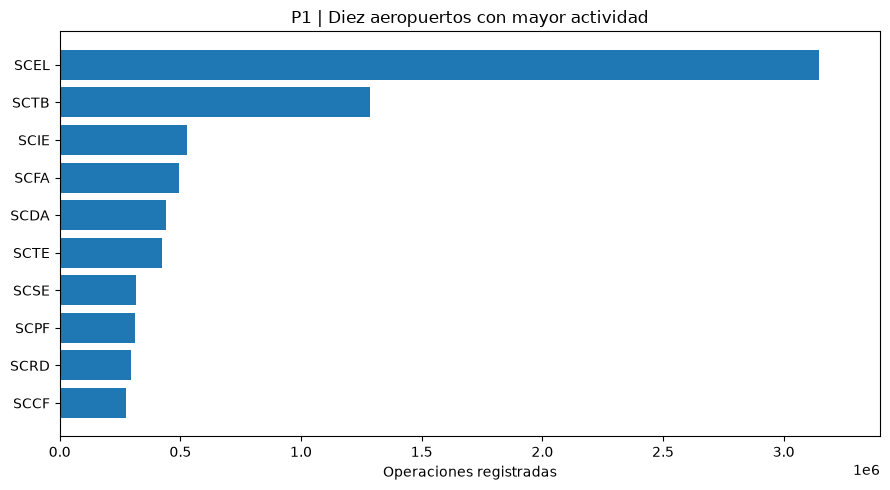

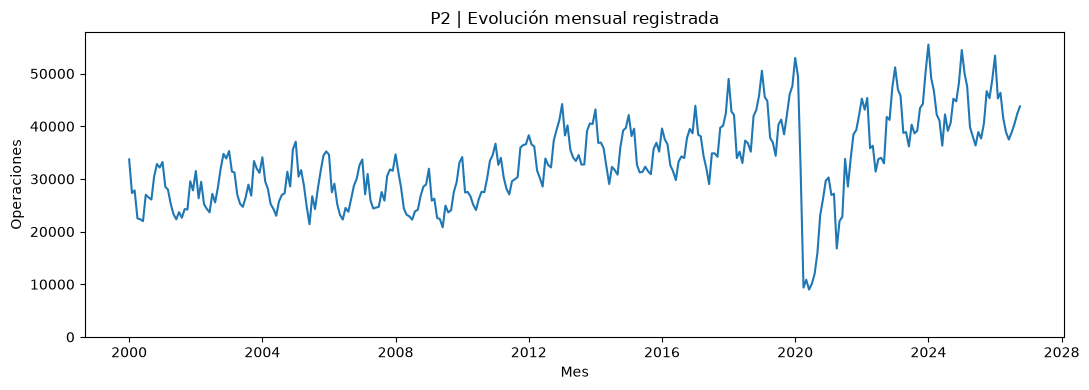

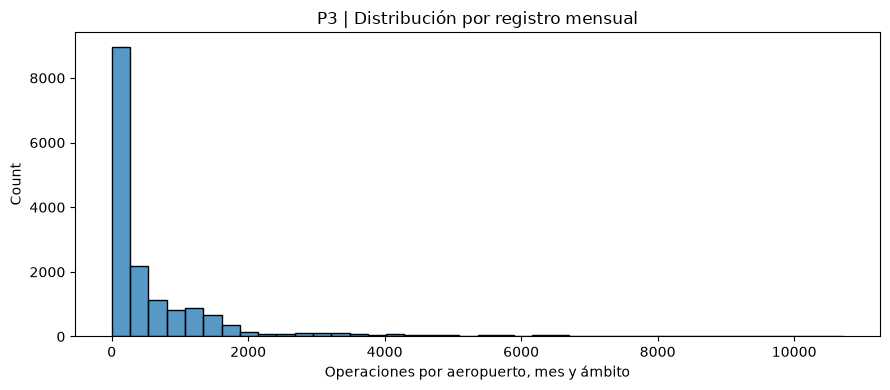

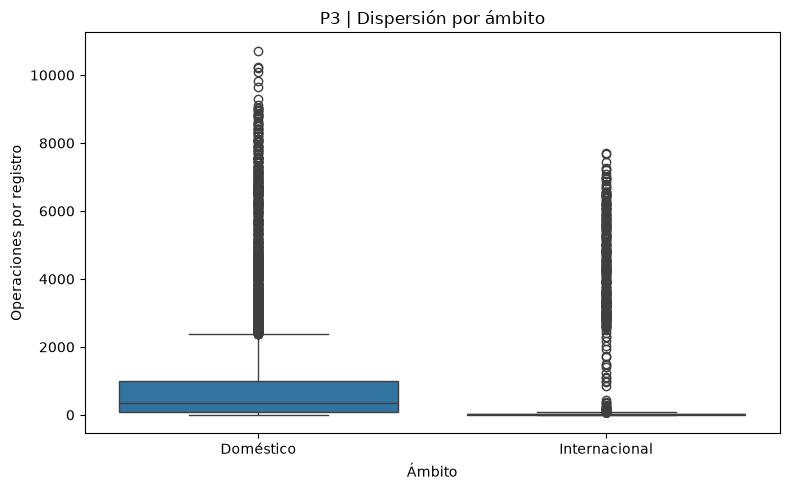

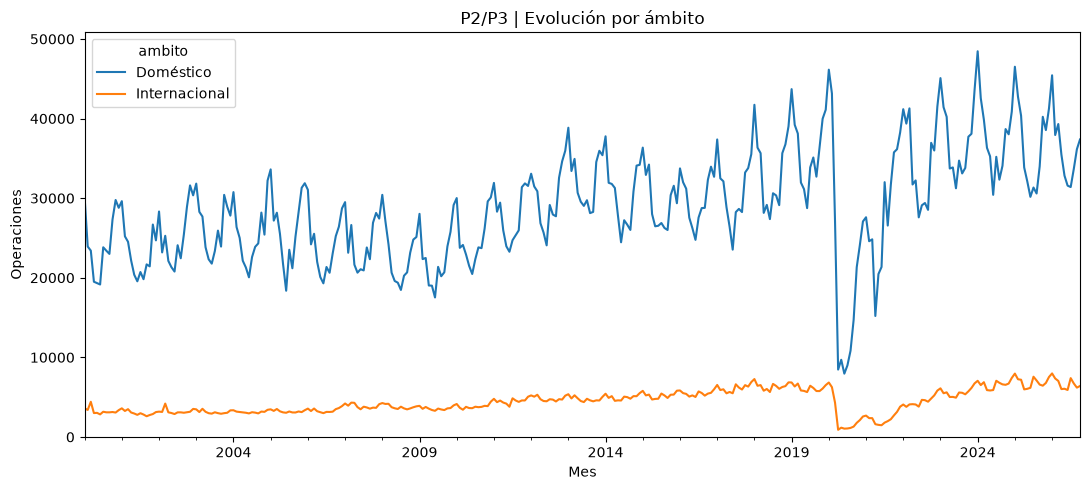

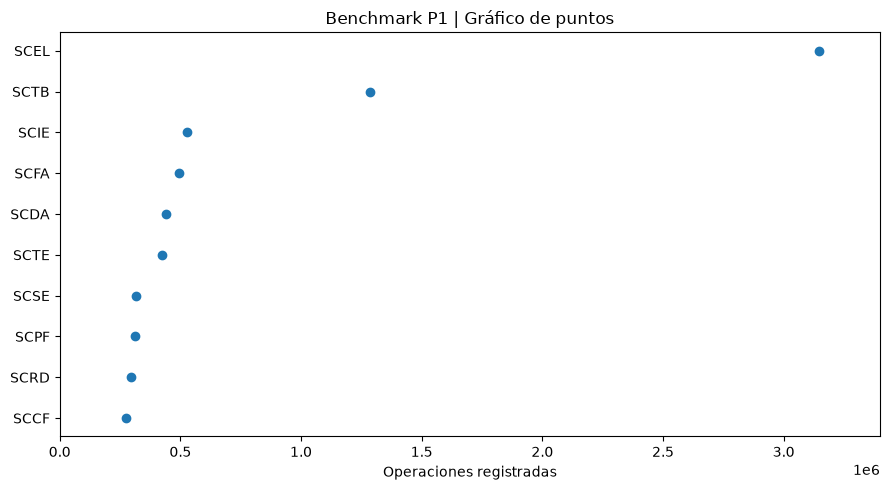

In [6]:
def save(fig,name):
    fig.tight_layout(); fig.savefig(FIG/(name+'.png'),dpi=160,bbox_inches='tight'); plt.show(); plt.close(fig)
top=ranking.head(10).sort_values('total')
fig,ax=plt.subplots(figsize=(9,5)); ax.barh(top.index,top.total); ax.set(xlabel='Operaciones registradas',title='P1 | Diez aeropuertos con mayor actividad',xlim=(0,top.total.max()*1.08)); save(fig,'01_barras')
fig,ax=plt.subplots(figsize=(11,4)); ax.plot(monthly.asfreq('MS')); ax.set(title='P2 | Evolución mensual registrada',ylabel='Operaciones',xlabel='Mes'); ax.set_ylim(bottom=0); save(fig,'02_linea')
fig,ax=plt.subplots(figsize=(9,4)); sns.histplot(data=d,x='cnt_operaciones',bins=40,ax=ax); ax.set(title='P3 | Distribución por registro mensual',xlabel='Operaciones por aeropuerto, mes y ámbito'); save(fig,'03_histograma')
fig,ax=plt.subplots(figsize=(8,5)); sns.boxplot(data=d,x='ambito',y='cnt_operaciones',ax=ax); ax.set(title='P3 | Dispersión por ámbito',xlabel='Ámbito',ylabel='Operaciones por registro'); save(fig,'04_cajas')
fig,ax=plt.subplots(figsize=(11,5)); pivot.asfreq('MS').plot(ax=ax); ax.set(title='P2/P3 | Evolución por ámbito',xlabel='Mes',ylabel='Operaciones'); ax.set_ylim(bottom=0); save(fig,'05_multidimensional')
fig,ax=plt.subplots(figsize=(9,5)); ax.scatter(top.total,top.index); ax.set(xlabel='Operaciones registradas',title='Benchmark P1 | Gráfico de puntos',xlim=(0,top.total.max()*1.08)); save(fig,'06_puntos')


## Canales y benchmark
Mes → posición X (orden temporal); operaciones → posición Y (magnitud); ámbito → color (categorías). Agregar aeropuerto como otra línea dificultaría seguir cada serie; facetas serían preferibles.

| Criterio | Barras | Puntos |
|---|---|---|
| Claridad | Longitud directa | Posición directa |
| Precisión | Buena escala común | Buena escala común |
| Comparabilidad | Alta | Alta |
| Densidad | Menor | Mayor |
| Carga cognitiva | Baja | Baja |
| Utilidad | Ranking general | Comparación compacta |

Se eligen barras para audiencia general por familiaridad. Ambas muestran los mismos diez aeropuertos y escala desde cero.
## Validación
Gráfico 1: propósito ranking; audiencia planificación; sumas verificadas contra total; escala cero; color uniforme; etiquetas OACI; top 10 puede ocultar cola, por eso se publica ranking completo. Gráfico 2: propósito evolución; audiencia analistas; sumas mensuales validadas; escala cero, color único, meses sin registros no se imputan. Un mes parcial puede aparentar caída; no interpretar como descenso definitivo sin verificar cobertura. Ninguno mide pasajeros, demanda insatisfecha ni causalidad.

In [7]:
total=d.cnt_operaciones.sum(); assert total>0
leader=ranking.index[0]; share=ranking.total.iloc[0]/total*100
peak=monthly.idxmax(); peak_value=monthly.max()
by=d.groupby('ambito').cnt_operaciones.sum().sort_values(ascending=False)
q=d.cnt_operaciones.quantile([.25,.5,.75]); skew=d.cnt_operaciones.skew(); extremes=(d.cnt_operaciones>q.loc[.75]+1.5*(q.loc[.75]-q.loc[.25])).sum()
findings=f"""# Hallazgos observados
1. Concentración: {leader} registra {ranking.total.iloc[0]:,.0f} movimientos ({share:.2f}% del total). Figura 01. Permite priorizar revisión de infraestructura; no demuestra saturación.
2. Evolución: máximo mensual en {peak:%Y-%m}: {peak_value:,.0f} movimientos. Figura 02. Orienta revisión de capacidad estacional; cobertura desigual o meses parciales pueden afectar comparación.
3. Segmentación: {by.index[0]} concentra {by.iloc[0]:,.0f} movimientos ({by.iloc[0]/total:.2%}). Figuras 04 y 05. Útil para distinguir ámbitos; no equivale a pasajeros ni a vuelos únicos.
Distribución: mediana {q.loc[.5]:.1f}, Q1 {q.loc[.25]:.1f}, Q3 {q.loc[.75]:.1f}, asimetría {skew:.2f}, observaciones sobre límite superior IQR: {extremes}. Los extremos se conservan; no son errores confirmados.
Hipótesis: los diez mayores representan {ranking.total.head(10).sum()/total:.2%} del total; esta proporción describe concentración sin establecer un umbral previo de prueba.
Cobertura efectiva: {d.fecha.min():%Y-%m} a {d.fecha.max():%Y-%m}. Filas originales {len(df)}, retenidas {len(d)}.
"""
display(Markdown(findings)); (OUT/'hallazgos.md').write_text(findings,encoding='utf-8')


# Hallazgos observados
1. Concentración: SCEL registra 3,147,438 movimientos (29.34% del total). Figura 01. Permite priorizar revisión de infraestructura; no demuestra saturación.
2. Evolución: máximo mensual en 2024-01: 55,510 movimientos. Figura 02. Orienta revisión de capacidad estacional; cobertura desigual o meses parciales pueden afectar comparación.
3. Segmentación: Doméstico concentra 9,288,770 movimientos (86.60%). Figuras 04 y 05. Útil para distinguir ámbitos; no equivale a pasajeros ni a vuelos únicos.
Distribución: mediana 172.0, Q1 24.0, Q3 783.0, asimetría 3.49, observaciones sobre límite superior IQR: 1220. Los extremos se conservan; no son errores confirmados.
Hipótesis: los diez mayores representan 70.15% del total; esta proporción describe concentración sin establecer un umbral previo de prueba.
Cobertura efectiva: 2000-01 a 2026-10. Filas originales 16231, retenidas 16231.


905

## Ética y conclusiones
Se optó por conservar extremos válidos y separar claves ambiguas, en vez de imputar o sumar automáticamente. La auditoría muestra cuántas filas se afectan. Excluir extremos reduciría artificialmente la dispersión; excluir claves ambiguas puede reducir el volumen informado. Se declara la exclusión, la cobertura y el top 10; se mantienen originales y excluidos para revisión. Las conclusiones cuantitativas se generan en la celda anterior y no se atribuyen causas. Las operaciones registradas permiten describir concentración, evolución y ámbito, pero no representan todo el tráfico nacional.